In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve)

In [2]:
# CARGAR MODELOS

reg_log_diab_class_weight = joblib.load("../models/reg_log_diab_class_weight.joblib")
reg_log_diab = joblib.load("../models/reg_log_diab.joblib")
reg_log_diab_smote = joblib.load("../models/reg_log_diab_smote.joblib")

In [3]:
# CARGAR LOS DATOS DE TEST 

X_test_diab = pd.read_csv("../data/processed/X_test_diab_df.csv")
y_test_diab = pd.read_csv("../data/processed/y_test_diab.csv")

# REGRESIÓN LOGÍSTICA

INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)
              precision    recall  f1-score   support

           0     0.9687    0.7143    0.8223      3773
           1     0.2256    0.7830    0.3503       401

    accuracy                         0.7209      4174
   macro avg     0.5972    0.7487    0.5863      4174
weighted avg     0.8973    0.7209    0.7769      4174

ROC-AUC Score: 0.8146


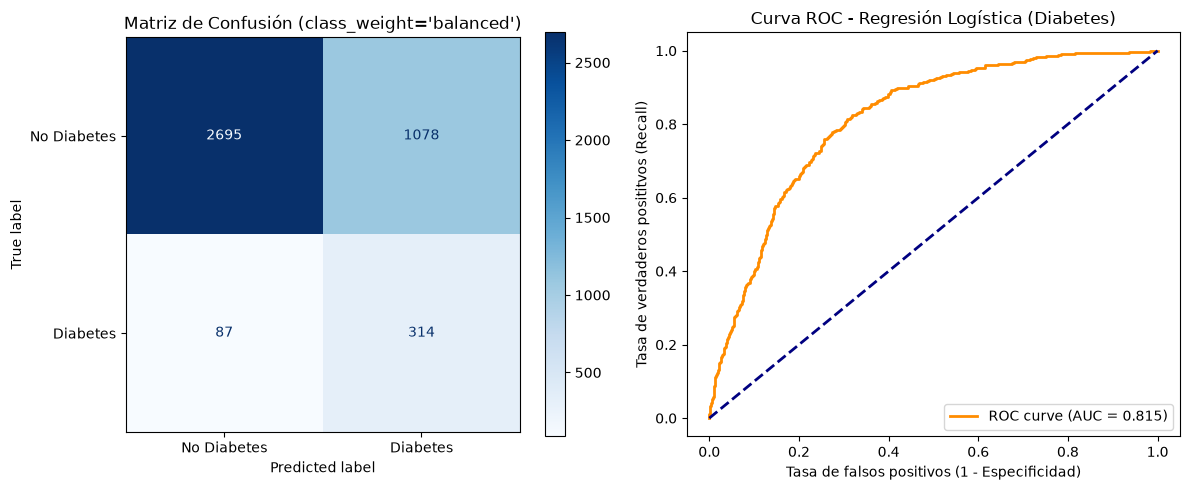

In [4]:
# ======================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS 
# ======================================================

# Predicciones 
y_pred_diab = reg_log_diab_class_weight.predict(X_test_diab)
y_pred_proba_diab = reg_log_diab_class_weight.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)")
print(classification_report(y_test_diab, y_pred_diab, digits=4))

auc_diab = roc_auc_score(y_test_diab, y_pred_proba_diab)
print(f"ROC-AUC Score: {auc_diab:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (class_weight='balanced')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_diab, y_pred_proba_diab)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_diab:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos posititvos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - DIABETES (Balanceado + Factor Adulto)
              precision    recall  f1-score   support

           0     0.9743    0.6721    0.7955      3773
           1     0.2126    0.8329    0.3387       401

    accuracy                         0.6876      4174
   macro avg     0.5934    0.7525    0.5671      4174
weighted avg     0.9011    0.6876    0.7516      4174

ROC-AUC Score: 0.8128


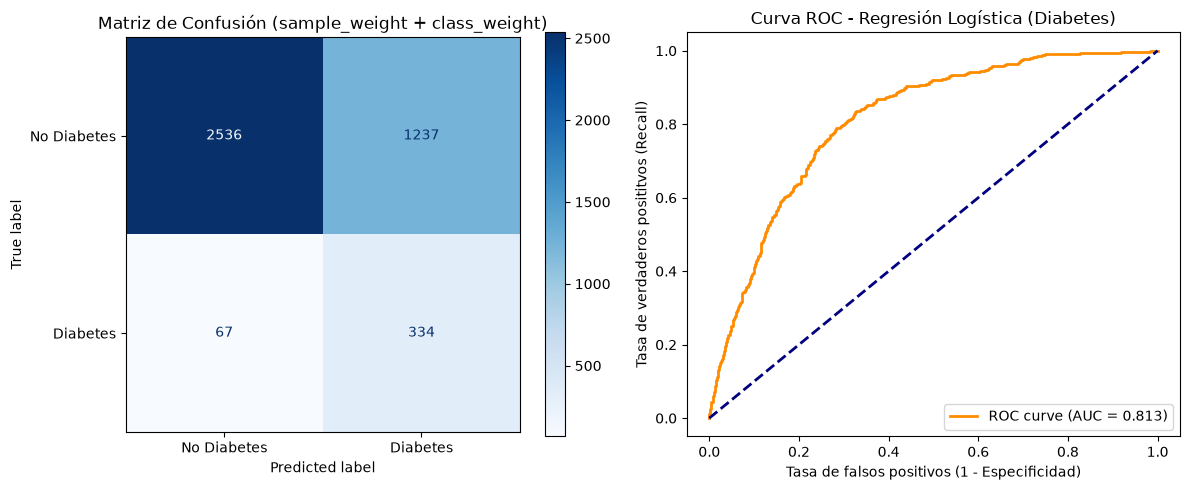

In [5]:
# =======================================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS Y FACTOR ADULTO
# =======================================================================

# Predicciones 
y_pred_diab = reg_log_diab.predict(X_test_diab)
y_pred_proba_diab = reg_log_diab.predict_proba(X_test_diab)[:, 1]

# Evaluación de métricas
print("INFORME DE CLASIFICACIÓN - DIABETES (Balanceado + Factor Adulto)")
print(classification_report(y_test_diab, y_pred_diab, digits=4))

auc_diab = roc_auc_score(y_test_diab, y_pred_proba_diab)
print(f"ROC-AUC Score: {auc_diab:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (sample_weight + class_weight)")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_diab, y_pred_proba_diab)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_diab:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos posititvos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


In [6]:
# 1. Obtenemos las probabilidades predichas (ya entrenado con 'balanced' + sample_weight)
y_proba_diab = reg_log_diab.predict_proba(X_test_diab)[:, 1]

# 2. Probamos distintos umbrales (ejemplo: 0.40, 0.45, 0.50, 0.55)
umbrales = [0.35, 0.40, 0.45, 0.50, 0.55]

for u in umbrales:
    y_pred_u = (y_proba_diab >= u).astype(int)
    report = classification_report(
        y_test_diab, y_pred_u, digits=4, output_dict=True
    )

    rec = report["1"]["recall"]
    prec = report["1"]["precision"]
    f1 = report["1"]["f1-score"]

    print(
        f"Umbral {u:.2f} -> Recall Diabetes: {rec*100:.2f}% | Precisión Diabetes: {prec*100:.2f}% | F1: {f1:.4f}"
    )

Umbral 0.35 -> Recall Diabetes: 90.52% | Precisión Diabetes: 17.46% | F1: 0.2927
Umbral 0.40 -> Recall Diabetes: 88.03% | Precisión Diabetes: 18.57% | F1: 0.3067
Umbral 0.45 -> Recall Diabetes: 85.29% | Precisión Diabetes: 19.88% | F1: 0.3225
Umbral 0.50 -> Recall Diabetes: 83.29% | Precisión Diabetes: 21.26% | F1: 0.3387
Umbral 0.55 -> Recall Diabetes: 79.30% | Precisión Diabetes: 22.35% | F1: 0.3487


DIABETES CON SMOTE
              precision    recall  f1-score   support

           0     0.9667    0.7315    0.8328      3773
           1     0.2320    0.7631    0.3558       401

    accuracy                         0.7345      4174
   macro avg     0.5994    0.7473    0.5943      4174
weighted avg     0.8961    0.7345    0.7870      4174

ROC-AUC Score: 0.8132


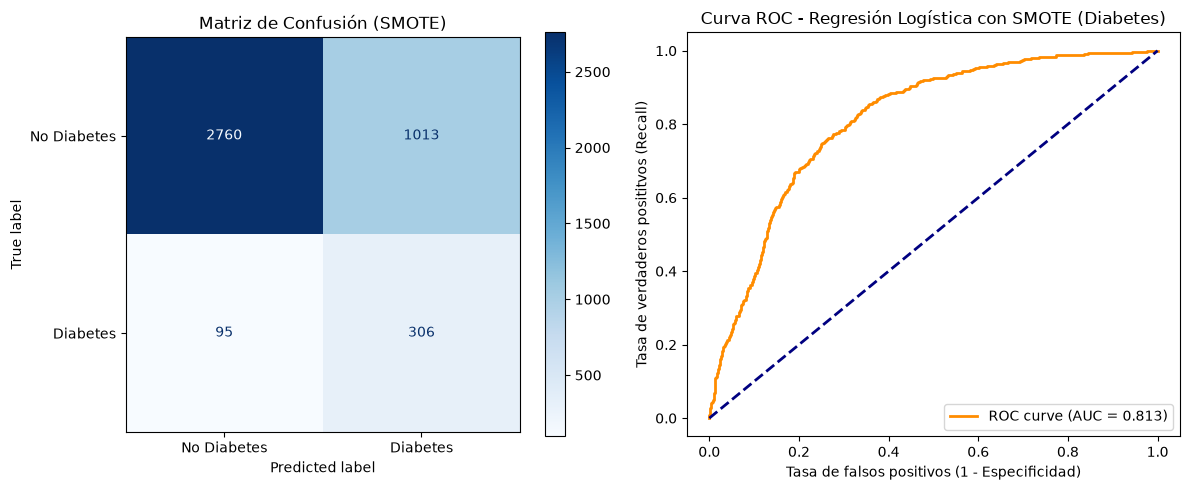

In [7]:
# ==========================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON SMOTE
# ==========================================

# Se evalua en el X_test original 
y_pred_diab_smote = reg_log_diab_smote.predict(X_test_diab)
y_proba_diab_smote = reg_log_diab_smote.predict_proba(X_test_diab)[:, 1]

print("DIABETES CON SMOTE")
print(classification_report(y_test_diab, y_pred_diab_smote, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test_diab, y_proba_diab_smote):.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (SMOTE)")

# Curva ROC
fpr_smote, tpr_smote, _ = roc_curve(y_test_diab, y_proba_diab_smote)
auc_smote = roc_auc_score(y_test_diab, y_proba_diab_smote)
axes[1].plot(fpr_smote, tpr_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_smote:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos posititvos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística con SMOTE (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### CONCLUSIONES

El modelo seleccionado como Baseline es el de class_weight='balanced' y FACTORADULTO, sobre el cual se aplicó una optimización de umbral de decisión en 0.40. Esta combinación maximiza la capacidad de detección temprana, alcanzando una Sensibilidad(Recall) del 88.03% en el grupo de riesgo de diabetes. Fue necesario bajar el umbral para no dejar pasar tantos enfermos. 
